DATASET LOADED
Dataset shape: (7043, 12)

Original columns:
['gender', 'SeniorCitizen', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'Contract', 'MonthlyCharges', 'Churn', 'Cluster', 'Customer_Segment']

Cleaned columns:
['gender', 'SeniorCitizen', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'Contract', 'MonthlyCharges', 'Churn', 'Cluster', 'Customer_Segment']

TotalCharges column not found.
TotalCharges created using tenure × MonthlyCharges.

NumServices column not found.
Available service columns: ['PhoneService', 'MultipleLines']
NumServices created successfully.

Churn_Flag column not found.
Churn_Flag created from Churn.

REQUIRED COLUMN CHECK
tenure - Available
MonthlyCharges - Available
TotalCharges - Available
NumServices - Available

Dataset shape after removing missing clustering values: (7043, 15)

Clustering features:
   tenure  MonthlyCharges  TotalCharges  NumServices
0       1              25            25   

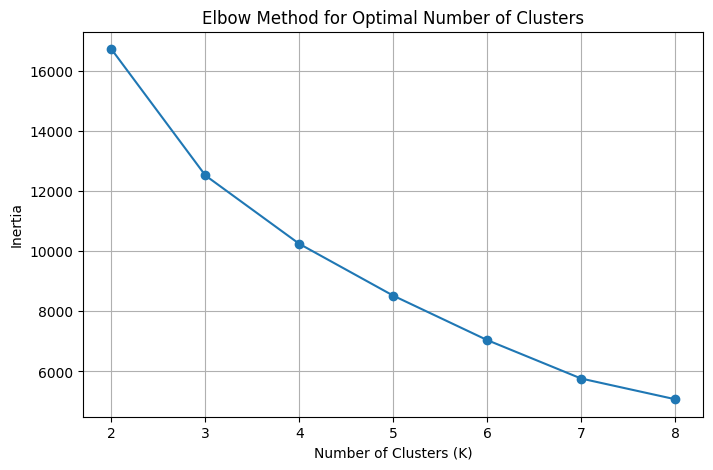

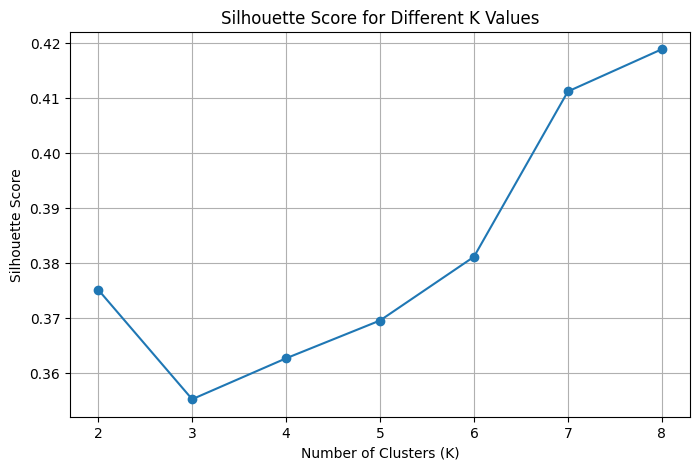


OPTIMAL CLUSTER RESULT
Optimal Number of Clusters: 8
Best Silhouette Score: 0.4188

Final K-Means model trained successfully.

Customers in each cluster:
Cluster
0    1003
1    1152
2     929
3     848
4    1335
5     629
6     745
7     402
Name: count, dtype: int64

Model saved as kmeans_model.pkl
Clustered dataset saved as telco_clustered.csv


In [4]:
# ============================================================
# PART 1
# LOAD DATA + PREPARE REQUIRED FIELDS + K-MEANS CLUSTERING
# ============================================================

# ------------------------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


# ------------------------------------------------------------
# 2. LOAD DATASET
# ------------------------------------------------------------

df = pd.read_csv("/content/Telecom_Customer_Clustering_Results.csv")

print("=" * 70)
print("DATASET LOADED")
print("=" * 70)

print("Dataset shape:", df.shape)

print("\nOriginal columns:")
print(df.columns.tolist())


# ------------------------------------------------------------
# 3. CLEAN COLUMN NAMES
# ------------------------------------------------------------

df.columns = df.columns.str.strip()

print("\nCleaned columns:")
print(df.columns.tolist())


# ------------------------------------------------------------
# 4. CREATE / FIX TotalCharges
# ------------------------------------------------------------

if "TotalCharges" not in df.columns:

    print("\nTotalCharges column not found.")

    # Create approximate TotalCharges if tenure and MonthlyCharges exist
    if "tenure" in df.columns and "MonthlyCharges" in df.columns:

        df["TotalCharges"] = (
            df["tenure"] * df["MonthlyCharges"]
        )

        print(
            "TotalCharges created using "
            "tenure × MonthlyCharges."
        )

else:

    df["TotalCharges"] = pd.to_numeric(
        df["TotalCharges"],
        errors="coerce"
    )


# ------------------------------------------------------------
# 5. CREATE NumServices
# ------------------------------------------------------------

if "NumServices" not in df.columns:

    print("\nNumServices column not found.")

    service_columns = [
        "PhoneService",
        "MultipleLines",
        "OnlineSecurity",
        "OnlineBackup",
        "DeviceProtection",
        "TechSupport",
        "StreamingTV",
        "StreamingMovies"
    ]

    available_services = [
        col for col in service_columns
        if col in df.columns
    ]

    print(
        "Available service columns:",
        available_services
    )

    def count_services(row):

        count = 0

        for col in available_services:

            value = str(row[col]).strip().lower()

            if value == "yes":
                count += 1

        return count

    df["NumServices"] = df.apply(
        count_services,
        axis=1
    )

    print(
        "NumServices created successfully."
    )


# ------------------------------------------------------------
# 6. CREATE Churn_Flag IF NEEDED
# ------------------------------------------------------------

if "Churn_Flag" not in df.columns:

    print("\nChurn_Flag column not found.")

    if "Churn" in df.columns:

        df["Churn_Flag"] = (
            df["Churn"]
            .astype(str)
            .str.strip()
            .str.lower()
            .map({
                "yes": 1,
                "no": 0
            })
        )

        print(
            "Churn_Flag created from Churn."
        )


# ------------------------------------------------------------
# 7. CHECK REQUIRED COLUMNS
# ------------------------------------------------------------

required_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "NumServices"
]

print("\n" + "=" * 70)
print("REQUIRED COLUMN CHECK")
print("=" * 70)

for column in required_columns:

    if column in df.columns:
        print(column, "- Available")

    else:
        print(column, "- NOT AVAILABLE")


# ------------------------------------------------------------
# 8. REMOVE MISSING VALUES FOR CLUSTERING FEATURES
# ------------------------------------------------------------

df["tenure"] = pd.to_numeric(
    df["tenure"],
    errors="coerce"
)

df["MonthlyCharges"] = pd.to_numeric(
    df["MonthlyCharges"],
    errors="coerce"
)

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

df["NumServices"] = pd.to_numeric(
    df["NumServices"],
    errors="coerce"
)

df = df.dropna(
    subset=required_columns
).copy()

print(
    "\nDataset shape after removing missing clustering values:",
    df.shape
)


# ------------------------------------------------------------
# 9. SELECT FEATURES
# ------------------------------------------------------------

cluster_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "NumServices"
]

X_cluster = df[
    cluster_features
].copy()

print("\nClustering features:")
print(X_cluster.head())

print("\nSummary:")
print(X_cluster.describe())


# ------------------------------------------------------------
# 10. SCALE FEATURES
# ------------------------------------------------------------

scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    X_cluster
)

print(
    "\nFeature scaling completed successfully."
)


# ------------------------------------------------------------
# 11. TEST DIFFERENT K VALUES
# ------------------------------------------------------------

k_values = range(2, 9)

inertia_values = []
silhouette_values = []

for k in k_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(
        X_scaled
    )

    inertia_values.append(
        model.inertia_
    )

    silhouette_values.append(
        silhouette_score(
            X_scaled,
            labels
        )
    )


# ------------------------------------------------------------
# 12. RESULTS TABLE
# ------------------------------------------------------------

cluster_results = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia_values,
    "Silhouette_Score": silhouette_values
})

print("\n" + "=" * 70)
print("CLUSTER TEST RESULTS")
print("=" * 70)

print(
    cluster_results.round(4)
)


# ------------------------------------------------------------
# 13. ELBOW METHOD
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.title(
    "Elbow Method for Optimal Number of Clusters"
)

plt.xlabel(
    "Number of Clusters (K)"
)

plt.ylabel(
    "Inertia"
)

plt.grid()

plt.show()


# ------------------------------------------------------------
# 14. SILHOUETTE SCORE
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    silhouette_values,
    marker="o"
)

plt.title(
    "Silhouette Score for Different K Values"
)

plt.xlabel(
    "Number of Clusters (K)"
)

plt.ylabel(
    "Silhouette Score"
)

plt.grid()

plt.show()


# ------------------------------------------------------------
# 15. FIND OPTIMAL K
# ------------------------------------------------------------

best_index = np.argmax(
    silhouette_values
)

optimal_k = list(k_values)[
    best_index
]

best_silhouette = silhouette_values[
    best_index
]

print("\n" + "=" * 70)
print("OPTIMAL CLUSTER RESULT")
print("=" * 70)

print(
    "Optimal Number of Clusters:",
    optimal_k
)

print(
    "Best Silhouette Score:",
    round(best_silhouette, 4)
)


# ------------------------------------------------------------
# 16. TRAIN FINAL K-MEANS MODEL
# ------------------------------------------------------------

kmeans_model = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

df["Cluster"] = (
    kmeans_model.fit_predict(
        X_scaled
    )
)

print(
    "\nFinal K-Means model trained successfully."
)

print("\nCustomers in each cluster:")

print(
    df["Cluster"]
    .value_counts()
    .sort_index()
)


# ------------------------------------------------------------
# 17. SAVE MODEL
# ------------------------------------------------------------

model_data = {
    "model": kmeans_model,
    "scaler": scaler,
    "features": cluster_features,
    "optimal_k": optimal_k
}

with open(
    "kmeans_model.pkl",
    "wb"
) as file:

    pickle.dump(
        model_data,
        file
    )

print(
    "\nModel saved as kmeans_model.pkl"
)


# ------------------------------------------------------------
# 18. SAVE CLUSTERED DATASET
# ------------------------------------------------------------

df.to_csv(
    "telco_clustered.csv",
    index=False
)

print(
    "Clustered dataset saved as "
    "telco_clustered.csv"
)

CLUSTERED DATASET LOADED
Dataset shape: (7043, 12)

Columns available:
['gender', 'SeniorCitizen', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'Contract', 'MonthlyCharges', 'Churn', 'Cluster', 'Customer_Segment']

Cluster distribution:
Cluster
0    1704
1    1930
2    2245
3    1164
Name: count, dtype: int64

TotalCharges not found.
TotalCharges recreated successfully.

NumServices not found.
Available service columns:
['PhoneService', 'MultipleLines']
NumServices recreated successfully.

Churn_Flag not found.
Churn_Flag recreated successfully.

SAVED MODEL INFORMATION
Features expected by model:
['tenure', 'MonthlyCharges', 'TotalCharges', 'NumServices']
Saved optimal K:
8

Feature check:
tenure - Available
MonthlyCharges - Available
TotalCharges - Available
NumServices - Available

Clustering data shape:
(7043, 4)

Data scaled successfully.

Clusters regenerated using saved model.

New cluster distribution:
Cluster
0    1003
1    1152
2     929
3     8

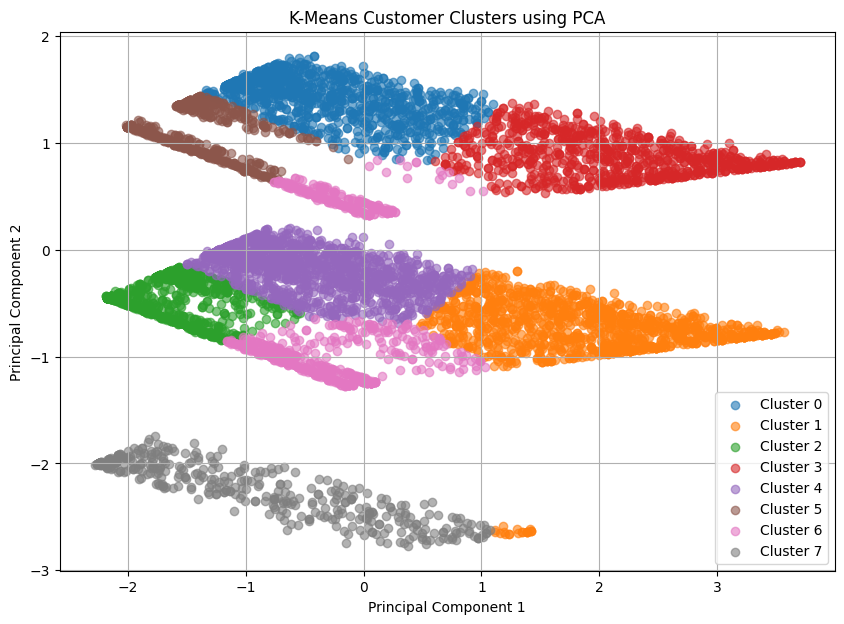


CLUSTER PROFILE
   Cluster  Customers  AverageTenure  AverageMonthlyCharges  \
0        0       1003          15.79                  79.94   
1        1       1152          58.68                  91.39   
2        2        929          10.80                  31.15   
3        3        848          59.84                  92.98   
4        4       1335          15.92                  79.91   
5        5        629          12.78                  29.80   
6        6        745          56.76                  28.04   
7        7        402          30.33                  41.18   

   AverageTotalCharges  AverageServices  ChurnRate  
0              1254.43             2.00      46.56  
1              5352.46             0.98      14.32  
2               307.20             1.00      22.50  
3              5564.85             2.00      16.27  
4              1265.23             1.00      47.72  
5               336.01             2.00      18.76  
6              1565.88             1.31     

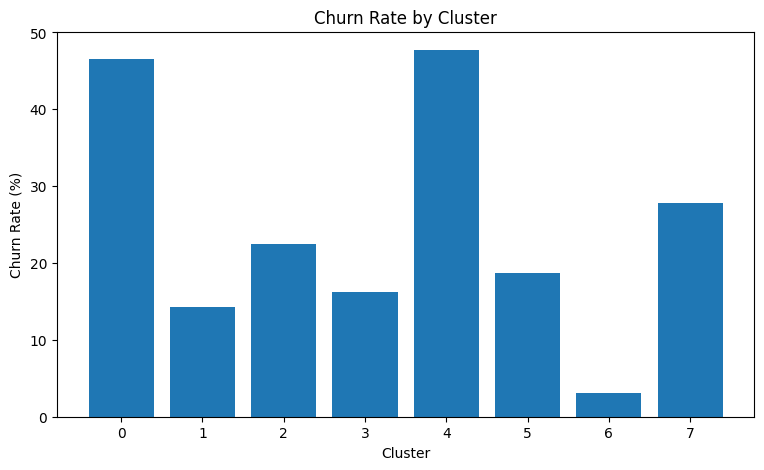

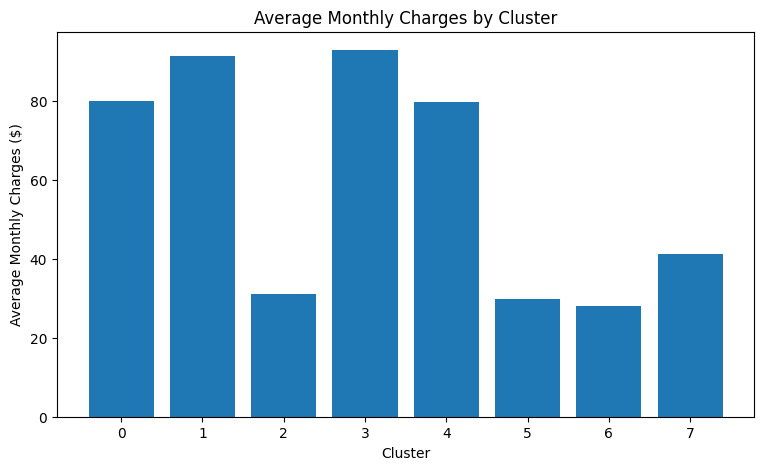

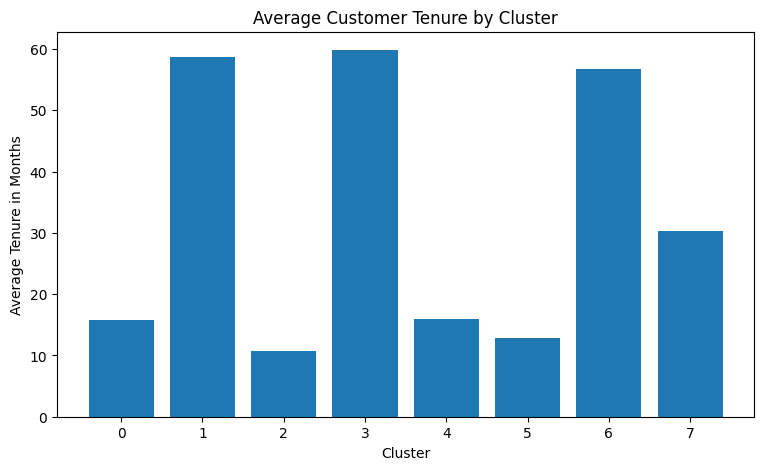

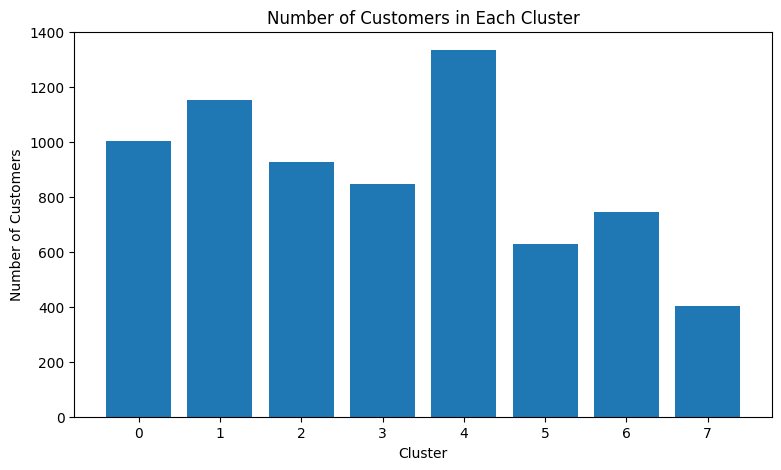


HIGHEST CHURN RISK CLUSTER
Cluster: 4
Customers: 1335
Average Tenure: 15.92 months
Average Monthly Charges: $ 79.91
Average Number of Services: 1.0
Churn Rate: 47.72 %

Files saved successfully:
telco_final_clusters.csv
cluster_profile.csv


In [6]:
# ============================================================
# PART 2
# LOAD CLUSTERED DATA + VISUALISE + LABEL + INTERPRET
# ============================================================

# ------------------------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle

from sklearn.decomposition import PCA


# ------------------------------------------------------------
# 2. LOAD CLUSTERED DATASET
# ------------------------------------------------------------

df = pd.read_csv(
    "/content/Telecom_Customer_Clustering_Results.csv"
)

print("=" * 70)
print("CLUSTERED DATASET LOADED")
print("=" * 70)

print("Dataset shape:", df.shape)

print("\nColumns available:")
print(df.columns.tolist())

print("\nCluster distribution:")
print(df["Cluster"].value_counts().sort_index())


# ------------------------------------------------------------
# 3. CLEAN COLUMN NAMES
# ------------------------------------------------------------

df.columns = df.columns.str.strip()


# ------------------------------------------------------------
# 4. RECREATE TotalCharges IF MISSING
# ------------------------------------------------------------

if "TotalCharges" not in df.columns:

    print("\nTotalCharges not found.")

    df["TotalCharges"] = (
        pd.to_numeric(df["tenure"], errors="coerce")
        *
        pd.to_numeric(df["MonthlyCharges"], errors="coerce")
    )

    print("TotalCharges recreated successfully.")


# ------------------------------------------------------------
# 5. RECREATE NumServices IF MISSING
# ------------------------------------------------------------

if "NumServices" not in df.columns:

    print("\nNumServices not found.")

    service_columns = [
        "PhoneService",
        "MultipleLines",
        "OnlineSecurity",
        "OnlineBackup",
        "DeviceProtection",
        "TechSupport",
        "StreamingTV",
        "StreamingMovies"
    ]

    available_services = [
        col for col in service_columns
        if col in df.columns
    ]

    print("Available service columns:")
    print(available_services)

    def count_services(row):

        count = 0

        for col in available_services:

            value = str(row[col]).strip().lower()

            if value == "yes":
                count += 1

        return count

    df["NumServices"] = df.apply(
        count_services,
        axis=1
    )

    print("NumServices recreated successfully.")


# ------------------------------------------------------------
# 6. RECREATE Churn_Flag IF MISSING
# ------------------------------------------------------------

if "Churn_Flag" not in df.columns:

    print("\nChurn_Flag not found.")

    if "Churn" in df.columns:

        df["Churn_Flag"] = (
            df["Churn"]
            .astype(str)
            .str.strip()
            .str.lower()
            .map({
                "yes": 1,
                "no": 0
            })
        )

        print("Churn_Flag recreated successfully.")


# ------------------------------------------------------------
# 7. LOAD SAVED MODEL
# ------------------------------------------------------------

with open("kmeans_model.pkl", "rb") as file:

    saved_model = pickle.load(file)

kmeans_model = saved_model["model"]
scaler = saved_model["scaler"]
cluster_features = saved_model["features"]
optimal_k = saved_model["optimal_k"]

print("\n" + "=" * 70)
print("SAVED MODEL INFORMATION")
print("=" * 70)

print("Features expected by model:")
print(cluster_features)

print("Saved optimal K:")
print(optimal_k)


# ------------------------------------------------------------
# 8. CHECK MODEL FEATURES
# ------------------------------------------------------------

print("\nFeature check:")

for col in cluster_features:

    if col in df.columns:
        print(col, "- Available")

    else:
        print(col, "- MISSING")


# ------------------------------------------------------------
# 9. PREPARE CLUSTERING FEATURES
# ------------------------------------------------------------

for col in cluster_features:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

df = df.dropna(
    subset=cluster_features
).copy()

X_cluster = df[
    cluster_features
].copy()

print("\nClustering data shape:")
print(X_cluster.shape)


# ------------------------------------------------------------
# 10. SCALE DATA USING SAVED SCALER
# ------------------------------------------------------------

X_scaled = scaler.transform(
    X_cluster
)

print("\nData scaled successfully.")


# ------------------------------------------------------------
# 11. GENERATE CLUSTERS AGAIN FROM SAVED MODEL
# ------------------------------------------------------------

df["Cluster"] = kmeans_model.predict(
    X_scaled
)

print("\nClusters regenerated using saved model.")

print("\nNew cluster distribution:")
print(
    df["Cluster"]
    .value_counts()
    .sort_index()
)


# ------------------------------------------------------------
# 12. PCA FOR 2D VISUALISATION
# ------------------------------------------------------------

pca = PCA(
    n_components=2
)

pca_values = pca.fit_transform(
    X_scaled
)

df["PCA1"] = pca_values[:, 0]
df["PCA2"] = pca_values[:, 1]


# ------------------------------------------------------------
# 13. CLUSTER SCATTER PLOT
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

for cluster in sorted(
    df["Cluster"].unique()
):

    cluster_data = df[
        df["Cluster"] == cluster
    ]

    plt.scatter(
        cluster_data["PCA1"],
        cluster_data["PCA2"],
        label=f"Cluster {cluster}",
        alpha=0.6
    )

plt.title("K-Means Customer Clusters using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid()

plt.show()


# ------------------------------------------------------------
# 14. CREATE CLUSTER PROFILE
# ------------------------------------------------------------

cluster_profile = df.groupby(
    "Cluster"
).agg(

    Customers=(
        "Cluster",
        "count"
    ),

    AverageTenure=(
        "tenure",
        "mean"
    ),

    AverageMonthlyCharges=(
        "MonthlyCharges",
        "mean"
    ),

    AverageTotalCharges=(
        "TotalCharges",
        "mean"
    ),

    AverageServices=(
        "NumServices",
        "mean"
    ),

    ChurnRate=(
        "Churn_Flag",
        "mean"
    )

).reset_index()

cluster_profile["ChurnRate"] = (
    cluster_profile["ChurnRate"] * 100
)

print("\n" + "=" * 80)
print("CLUSTER PROFILE")
print("=" * 80)

print(cluster_profile.round(2))


# ------------------------------------------------------------
# 15. CREATE CLUSTER LABELS
# ------------------------------------------------------------

overall_tenure = df["tenure"].mean()

overall_monthly_charge = (
    df["MonthlyCharges"].mean()
)

overall_churn_rate = (
    df["Churn_Flag"].mean() * 100
)


def create_cluster_label(row):

    if row["AverageTenure"] < overall_tenure:
        tenure_label = "Newer Customers"
    else:
        tenure_label = "Long-Term Customers"

    if row["AverageMonthlyCharges"] < overall_monthly_charge:
        spending_label = "Lower Spend"
    else:
        spending_label = "Higher Spend"

    if row["ChurnRate"] > overall_churn_rate:
        churn_label = "High Churn Risk"
    else:
        churn_label = "Low Churn Risk"

    return (
        tenure_label
        + " | "
        + spending_label
        + " | "
        + churn_label
    )


cluster_profile["ClusterLabel"] = (
    cluster_profile.apply(
        create_cluster_label,
        axis=1
    )
)

print("\n" + "=" * 80)
print("CLUSTER LABELS")
print("=" * 80)

print(
    cluster_profile[
        [
            "Cluster",
            "Customers",
            "AverageTenure",
            "AverageMonthlyCharges",
            "AverageServices",
            "ChurnRate",
            "ClusterLabel"
        ]
    ].round(2)
)


# ------------------------------------------------------------
# 16. CHURN RATE BY CLUSTER
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.bar(
    cluster_profile["Cluster"].astype(str),
    cluster_profile["ChurnRate"]
)

plt.title("Churn Rate by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Churn Rate (%)")

plt.show()


# ------------------------------------------------------------
# 17. AVERAGE MONTHLY CHARGE BY CLUSTER
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.bar(
    cluster_profile["Cluster"].astype(str),
    cluster_profile["AverageMonthlyCharges"]
)

plt.title("Average Monthly Charges by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Average Monthly Charges ($)")

plt.show()


# ------------------------------------------------------------
# 18. AVERAGE TENURE BY CLUSTER
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.bar(
    cluster_profile["Cluster"].astype(str),
    cluster_profile["AverageTenure"]
)

plt.title("Average Customer Tenure by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Average Tenure in Months")

plt.show()


# ------------------------------------------------------------
# 19. NUMBER OF CUSTOMERS BY CLUSTER
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.bar(
    cluster_profile["Cluster"].astype(str),
    cluster_profile["Customers"]
)

plt.title("Number of Customers in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")

plt.show()


# ------------------------------------------------------------
# 20. FIND HIGHEST CHURN RISK CLUSTER
# ------------------------------------------------------------

highest_risk_cluster = (
    cluster_profile
    .sort_values(
        "ChurnRate",
        ascending=False
    )
    .iloc[0]
)

print("\n" + "=" * 80)
print("HIGHEST CHURN RISK CLUSTER")
print("=" * 80)

print(
    "Cluster:",
    int(highest_risk_cluster["Cluster"])
)

print(
    "Customers:",
    int(highest_risk_cluster["Customers"])
)

print(
    "Average Tenure:",
    round(
        highest_risk_cluster["AverageTenure"],
        2
    ),
    "months"
)

print(
    "Average Monthly Charges: $",
    round(
        highest_risk_cluster["AverageMonthlyCharges"],
        2
    )
)

print(
    "Average Number of Services:",
    round(
        highest_risk_cluster["AverageServices"],
        2
    )
)

print(
    "Churn Rate:",
    round(
        highest_risk_cluster["ChurnRate"],
        2
    ),
    "%"
)


# ------------------------------------------------------------
# 21. SAVE FINAL RESULTS
# ------------------------------------------------------------

cluster_label_map = dict(
    zip(
        cluster_profile["Cluster"],
        cluster_profile["ClusterLabel"]
    )
)

df["ClusterLabel"] = (
    df["Cluster"]
    .map(cluster_label_map)
)

df.to_csv(
    "telco_final_clusters.csv",
    index=False
)

cluster_profile.to_csv(
    "cluster_profile.csv",
    index=False
)

print("\nFiles saved successfully:")
print("telco_final_clusters.csv")
print("cluster_profile.csv")